# Demo đồ án: Mô hình Decision Tree (Cây quyết định)

**Đồ án cơ sở ngành** – Phạm Tuấn Khoa (110124095, DA24TTC) – GVHD: ThS. Ngô Thanh Huy

**Cách chạy trên Google Colab:** chọn **Runtime → Run all** (Thời gian chạy → Chạy tất cả). Toàn bộ chạy xong trong khoảng 10–20 giây, không cần cài thêm thư viện.

Nội dung demo:
1. Kiểm chứng ví dụ tính tay trên tập "Chơi tennis"
2. Huấn luyện cây quyết định trên tập Breast Cancer, so sánh cây mặc định và cây đã chọn tham số
3. Dự đoán một ca bệnh và giải thích từng bước đi trong cây
4. **Thử trực tiếp:** kéo thanh trượt để nhập số đo hoa Iris và xem cây dự đoán

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer, load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay, roc_auc_score
RANDOM_STATE = 42
plt.rcParams['figure.dpi'] = 100

## 1. Kiểm chứng ví dụ tính tay: tập "Chơi tennis"

In [2]:
tennis = pd.DataFrame({
    'Quang cảnh': ['Nắng','Nắng','U ám','Mưa','Mưa','Mưa','U ám','Nắng','Nắng','Mưa','Nắng','U ám','U ám','Mưa'],
    'Nhiệt độ':   ['Nóng','Nóng','Nóng','Ấm','Mát','Mát','Mát','Ấm','Mát','Ấm','Ấm','Ấm','Nóng','Ấm'],
    'Độ ẩm':      ['Cao','Cao','Cao','Cao','Bình thường','Bình thường','Bình thường','Cao','Bình thường','Bình thường','Bình thường','Cao','Bình thường','Cao'],
    'Gió':        ['Yếu','Mạnh','Yếu','Yếu','Yếu','Mạnh','Mạnh','Yếu','Yếu','Yếu','Mạnh','Mạnh','Yếu','Mạnh'],
    'Chơi tennis':['Không','Không','Có','Có','Có','Không','Có','Không','Có','Có','Có','Có','Có','Không']})

def entropy(y):
    p = y.value_counts(normalize=True); return float(-(p * np.log2(p)).sum())
def gini(y):
    p = y.value_counts(normalize=True); return float(1 - (p ** 2).sum())

H = entropy(tennis['Chơi tennis'])
rows = []
for a in ['Quang cảnh', 'Nhiệt độ', 'Độ ẩm', 'Gió']:
    rem = sum(len(g) / len(tennis) * entropy(g['Chơi tennis']) for _, g in tennis.groupby(a))
    gsp = sum(len(g) / len(tennis) * gini(g['Chơi tennis']) for _, g in tennis.groupby(a))
    rows.append({'Thuộc tính': a, 'Information Gain': round(H - rem, 3), 'Gini có trọng số': round(gsp, 3)})
print(f'H(S) = {H:.3f}')
pd.DataFrame(rows).sort_values('Information Gain', ascending=False)

H(S) = 0.940


,Thuộc tính,Information Gain,Gini có trọng số
0,Quang cảnh,0.247,0.343
2,Độ ẩm,0.152,0.367
3,Gió,0.048,0.429
1,Nhiệt độ,0.029,0.440


→ **Quang cảnh** có Information Gain lớn nhất (0,247) và Gini có trọng số nhỏ nhất (0,343), nên được chọn làm nút gốc, đúng như phần tính tay trong báo cáo.

## 2. Cây quyết định trên tập Breast Cancer Wisconsin
Lớp dương (1) là **malignant** (ác tính), lớp cần phát hiện.

In [3]:
d = load_breast_cancer(as_frame=True)
X, y = d.data, 1 - d.target            # 1 = malignant, 0 = benign
classes = ['benign (lành tính)', 'malignant (ác tính)']
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, stratify=y, random_state=RANDOM_STATE)
print('Số mẫu huấn luyện:', len(Xtr), '| Số mẫu kiểm tra:', len(Xte), '| Số thuộc tính:', X.shape[1])

default = DecisionTreeClassifier(random_state=RANDOM_STATE).fit(Xtr, ytr)
tuned = DecisionTreeClassifier(criterion='entropy', max_depth=3, min_samples_leaf=10, random_state=RANDOM_STATE).fit(Xtr, ytr)

res = []
for name, m in [('Cây mặc định', default), ('Cây đã chọn tham số', tuned)]:
    res.append({'Mô hình': name, 'Độ sâu': m.get_depth(), 'Số nút lá': m.get_n_leaves(),
                'Acc. huấn luyện': round(m.score(Xtr, ytr), 3), 'Acc. kiểm tra': round(m.score(Xte, yte), 3),
                'AUC': round(roc_auc_score(yte, m.predict_proba(Xte)[:, 1]), 3)})
pd.DataFrame(res)

Số mẫu huấn luyện: 398 | Số mẫu kiểm tra: 171 | Số thuộc tính: 30


,Mô hình,Độ sâu,Số nút lá,Acc. huấn luyện,Acc. kiểm tra,AUC
0,Cây mặc định,8,19,1.000,0.901,0.889
1,Cây đã chọn tham số,3,7,0.965,0.953,0.979


Cây mặc định đạt 100% trên tập huấn luyện nhưng thấp hơn trên tập kiểm tra (**quá khớp**). Cây đã chọn tham số nhỏ hơn nhiều mà dự đoán tốt hơn.

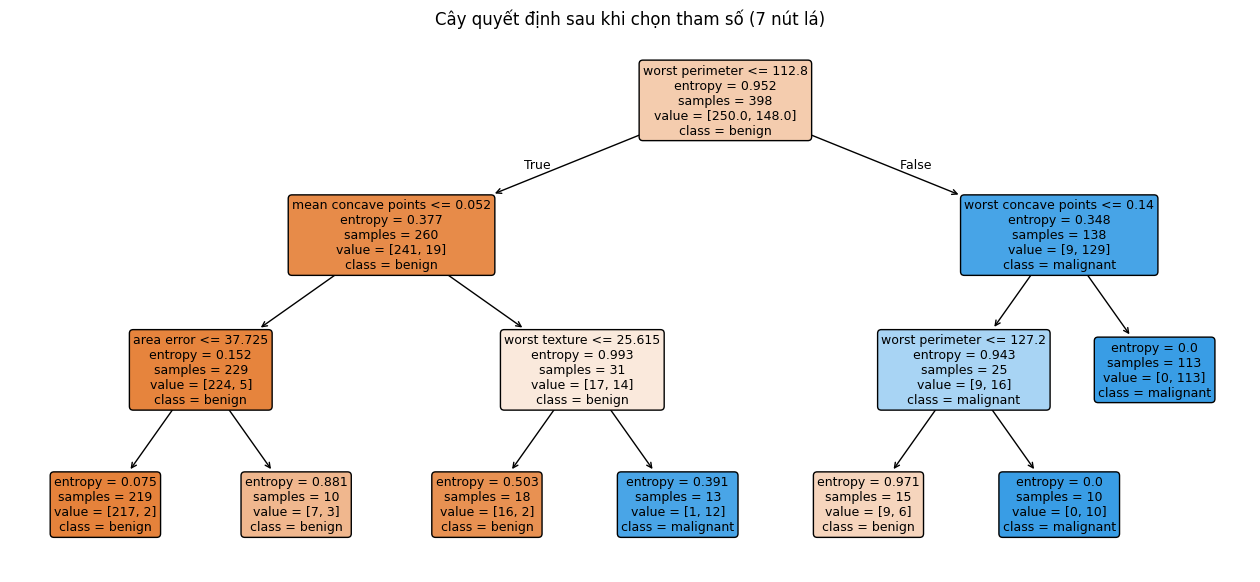

In [4]:
fig, ax = plt.subplots(figsize=(16, 7))
plot_tree(tuned, feature_names=list(X.columns), class_names=['benign', 'malignant'], filled=True, rounded=True, fontsize=9, ax=ax)
plt.title('Cây quyết định sau khi chọn tham số (7 nút lá)'); plt.show()

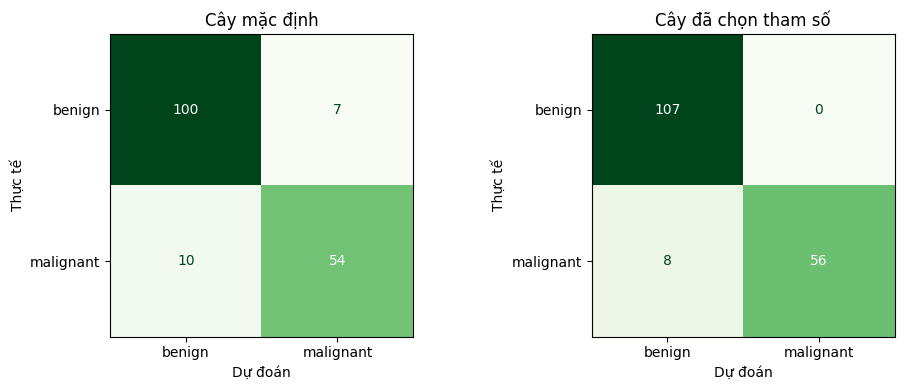

              precision    recall  f1-score   support

      benign      0.930     1.000     0.964       107
   malignant      1.000     0.875     0.933        64

    accuracy                          0.953       171
   macro avg      0.965     0.938     0.949       171
weighted avg      0.956     0.953     0.952       171



In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, m) in zip(axes, [('Cây mặc định', default), ('Cây đã chọn tham số', tuned)]):
    ConfusionMatrixDisplay.from_estimator(m, Xte, yte, display_labels=['benign', 'malignant'], cmap='Greens', colorbar=False, ax=ax)
    ax.set_title(name); ax.set_xlabel('Dự đoán'); ax.set_ylabel('Thực tế')
plt.tight_layout(); plt.show()
print(classification_report(yte, tuned.predict(Xte), target_names=['benign', 'malignant'], digits=3))

## 3. Dự đoán một ca bệnh và giải thích từng bước
Đổi số `idx` để thử ca khác trong tập kiểm tra.

In [6]:
def explain(model, x, feature_names, class_names):
    """In đường đi của mẫu x từ nút gốc đến nút lá."""
    t = model.tree_
    node_ids = model.decision_path(x.to_frame().T).indices
    for step, node in enumerate(node_ids, 1):
        if t.children_left[node] == t.children_right[node]:      # nút lá
            counts = t.value[node][0]; p = counts / counts.sum()
            print(f'  → Nút lá: dự đoán {class_names[int(np.argmax(p))].upper()} (xác suất {p.max():.0%}, nút có {t.n_node_samples[node]} mẫu huấn luyện)')
        else:
            f = feature_names[t.feature[node]]; thr = t.threshold[node]; v = x.iloc[t.feature[node]]
            print(f'Bước {step}: {f} = {v:.3f} {"≤" if v <= thr else ">"} {thr:.3f} → đi sang nhánh {"trái" if v <= thr else "phải"}')

idx = 0
x = Xte.iloc[idx]
print('Nhãn thực tế:', classes[int(yte.iloc[idx])]); print()
explain(tuned, x, list(X.columns), classes)

Nhãn thực tế: benign (lành tính)

Bước 1: worst perimeter = 108.100 ≤ 112.800 → đi sang nhánh trái
Bước 2: mean concave points = 0.029 ≤ 0.052 → đi sang nhánh trái
Bước 3: area error = 23.040 ≤ 37.725 → đi sang nhánh trái
  → Nút lá: dự đoán BENIGN (LÀNH TÍNH) (xác suất 99%, nút có 219 mẫu huấn luyện)


## 4. Thử trực tiếp với tập Iris
Kéo các thanh trượt để nhập số đo (cm) của một bông hoa. Cây (độ sâu 3) sẽ dự đoán loài và in ra đường đi trong cây.

In [7]:
iris = load_iris(as_frame=True)
Xi, yi = iris.data, iris.target
iris_tree = DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE).fit(Xi, yi)
print(export_text(iris_tree, feature_names=list(Xi.columns)))

|--- petal length (cm) <= 2.45
|   |--- class: 0
|--- petal length (cm) >  2.45
|   |--- petal width (cm) <= 1.75
|   |   |--- petal length (cm) <= 4.95
|   |   |   |--- class: 1
|   |   |--- petal length (cm) >  4.95
|   |   |   |--- class: 2
|   |--- petal width (cm) >  1.75
|   |   |--- petal length (cm) <= 4.85
|   |   |   |--- class: 2
|   |   |--- petal length (cm) >  4.85
|   |   |   |--- class: 2



In [8]:
import ipywidgets as widgets
from IPython.display import display

def predict_iris(sepal_length, sepal_width, petal_length, petal_width):
    x = pd.Series([sepal_length, sepal_width, petal_length, petal_width], index=Xi.columns)
    p = iris_tree.predict_proba(x.to_frame().T)[0]
    print(f'Dự đoán: {iris.target_names[np.argmax(p)].upper()}   (setosa {p[0]:.0%} | versicolor {p[1]:.0%} | virginica {p[2]:.0%})'); print()
    explain(iris_tree, x, list(Xi.columns), list(iris.target_names))

style = {'description_width': '130px'}; layout = widgets.Layout(width='420px')
widgets.interact(predict_iris,
    sepal_length=widgets.FloatSlider(value=5.8, min=4.0, max=8.0, step=0.1, description='Dài đài hoa', style=style, layout=layout),
    sepal_width =widgets.FloatSlider(value=3.0, min=2.0, max=4.5, step=0.1, description='Rộng đài hoa', style=style, layout=layout),
    petal_length=widgets.FloatSlider(value=4.3, min=1.0, max=7.0, step=0.1, description='Dài cánh hoa', style=style, layout=layout),
    petal_width =widgets.FloatSlider(value=1.3, min=0.1, max=2.5, step=0.1, description='Rộng cánh hoa', style=style, layout=layout));

interactive(children=(FloatSlider(value=5.8, description='Dài đài hoa', layout=Layout(width='420px'), max=8.0,…